# Phase 4: File I/O, Image Array Manipulation & Advanced Techniques
> **Target Audience:** Intermediate  
> **Prerequisites:** Phases 1, 2, and 3  
> **Key Goal:** Master file persistence, computer vision image manipulation as ndarrays, and memory optimization.

Welcome to **Phase 4** of the NumPy Guide! In production pipelines, arrays must be saved to disk, shared, and manipulated in computer vision workflows.

### In this notebook, you will learn:
1. **High-Performance Binary Persistence** – Fast `.npy` and compressed `.npz` storage.
2. **Text & CSV Data I/O** – `np.savetxt()` and `np.loadtxt()`.
3. **Images as NumPy Arrays** – Grayscale 2D arrays vs Color RGB 3D arrays.
4. **Procedural Graphic Generation** – Generating synthetic images and patterns in code.
5. **Image Array Transformations** – Inversion (light/dark mode), cropping ROI, and channel filtering.
6. **Performance & Memory Best Practices** – C-contiguous memory layouts and dtype efficiency.
7. **Capstone Challenge** – End-to-end data processing workflow.

## 1. High-Performance Binary File Persistence
NumPy's native `.npy` and `.npz` formats serialize data in binary, preserving exact dtypes and array shapes:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Create sample arrays
arr1 = np.array([[1, 2, 3], [4, 5, 6]])
arr2 = np.random.rand(3, 3)
arr3 = np.zeros((4, 4))

# 1. Save single array to .npy format
np.save('sample_arr1.npy', arr1)

# Load array back from disk
loaded_arr1 = np.load('sample_arr1.npy')
print("Loaded array 1 matches original:", np.array_equal(arr1, loaded_arr1))

# 2. Save multiple arrays compressed in a single .npz archive
np.savez_compressed('archive.npz', weights=arr1, features=arr2, mask=arr3)

# Inspect archive contents
archive = np.load('archive.npz')
print("Keys inside archive.npz:", archive.files)
print("Loaded weights shape   :", archive['weights'].shape)

Loaded array 1 matches original: True
Keys inside archive.npz: ['weights', 'features', 'mask']
Loaded weights shape   : (2, 3)


## 2. Text & CSV Data I/O
When interfacing with external databases or spreadsheets, use `np.savetxt` and `np.loadtxt`:

In [2]:
table_data = np.array([
    [101, 85.5, 92.0],
    [102, 78.0, 88.5],
    [103, 94.0, 96.5]
])

# Save to CSV with header and 2 decimal places
np.savetxt('grades.csv', table_data, delimiter=',', header='id,midterm,final', fmt='%.2f', comments='')

# Read back from CSV (skipping header row)
loaded_csv = np.loadtxt('grades.csv', delimiter=',', skiprows=1)
print("Loaded CSV Data:\n", loaded_csv)

Loaded CSV Data:
 [[101.   85.5  92. ]
 [102.   78.   88.5]
 [103.   94.   96.5]]


## 3. Computer Vision: Images as NumPy Arrays
Every digital image is fundamentally an `ndarray`:
- **Grayscale Image:** 2D array of shape `(Height, Width)` with pixel values between `0` (black) and `255` (white).
- **Color Image (RGB):** 3D array of shape `(Height, Width, 3)` where channels represent [Red, Green, Blue].

Let's programmatically generate a synthetic test image so our code runs anywhere with zero dependencies:

Image array shape: (120, 120), Dtype: float64
Min pixel value: 0.00, Max pixel value: 1.00
<string>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


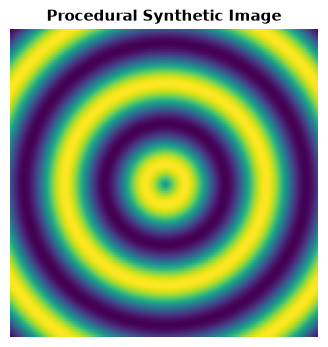

In [3]:
# Generate a procedural synthetic radial test pattern (120 x 120 pixels)
y, x = np.ogrid[-60:60, -60:60]
radius = np.sqrt(x**2 + y**2)

# Concentric rings normalized between 0.0 and 1.0
test_pattern = np.sin(radius / 5) * 0.5 + 0.5

print(f"Image array shape: {test_pattern.shape}, Dtype: {test_pattern.dtype}")
print(f"Min pixel value: {test_pattern.min():.2f}, Max pixel value: {test_pattern.max():.2f}")

# Display procedural image
plt.figure(figsize=(4, 4))
plt.imshow(test_pattern, cmap='viridis')
plt.title("Procedural Synthetic Image", fontsize=11, fontweight='bold')
plt.axis('off')
plt.show()

## 4. Image Array Manipulations & Transformations
Because images are arrays, image processing operations are simple matrix operations!

<string>:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


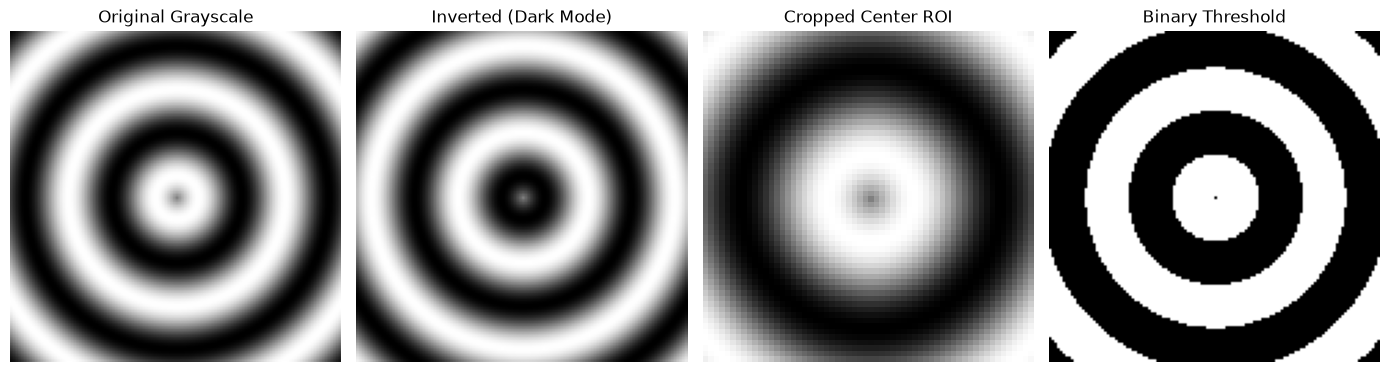

In [4]:
# 1. Inversion (Light mode to Dark mode / Negative image)
# Since values are [0.0, 1.0], inverted = 1.0 - image
dark_pattern = 1.0 - test_pattern

# 2. Cropping a Region of Interest (ROI) via 2D slicing
# Center 60x60 crop:
cropped_roi = test_pattern[30:90, 30:90]

# 3. Thresholding (Binarization): Pixels > 0.5 become 1.0, otherwise 0.0
binary_mask = np.where(test_pattern > 0.5, 1.0, 0.0)

# Multi-panel visualization
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(test_pattern, cmap='gray')
axes[0].set_title("Original Grayscale")
axes[0].axis('off')

axes[1].imshow(dark_pattern, cmap='gray')
axes[1].set_title("Inverted (Dark Mode)")
axes[1].axis('off')

axes[2].imshow(cropped_roi, cmap='gray')
axes[2].set_title("Cropped Center ROI")
axes[2].axis('off')

axes[3].imshow(binary_mask, cmap='gray')
axes[3].set_title("Binary Threshold")
axes[3].axis('off')

plt.tight_layout()
plt.show()

## 5. Performance & Memory Best Practices
### C-Contiguous vs Fortran-Contiguous Memory
NumPy arrays store elements row-by-row (C-style) by default. Slicing or transposing may create non-contiguous arrays, which can slow down operations:

In [5]:
arr_c = np.ones((1000, 1000))
print("C-contiguous flag :", arr_c.flags['C_CONTIGUOUS'])

# Transposing changes the memory layout to Fortran-contiguous:
arr_t = arr_c.T
print("Transposed C-flag :", arr_t.flags['C_CONTIGUOUS'])

# Force memory back into C-contiguous layout for maximum performance:
arr_realigned = np.ascontiguousarray(arr_t)
print("Realigned C-flag  :", arr_realigned.flags['C_CONTIGUOUS'])

C-contiguous flag : True
Transposed C-flag : False
Realigned C-flag  : True


## 6. Capstone Challenge
**Task:**
1. Generate a 100x100 synthetic RGB color image (shape `(100, 100, 3)`) where:
   - Red channel is a horizontal gradient from 0 to 255.
   - Green channel is a vertical gradient from 0 to 255.
   - Blue channel is fixed at 128.
2. Crop the center 50x50 block and save it to disk as `center_patch.npy`.
3. Load it back and display the cropped patch.

*Try coding your solution before checking below!*

<string>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


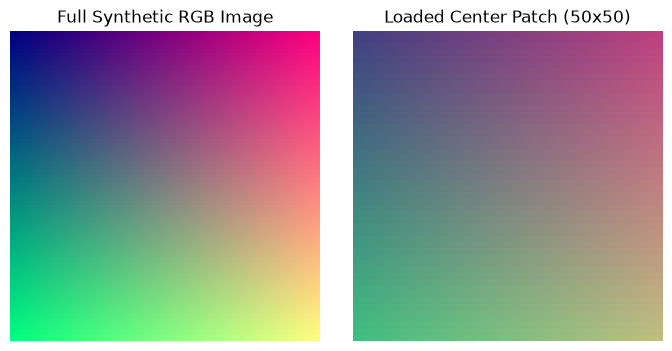

In [6]:
# Solution:
# Create coordinates
x_grad = np.linspace(0, 255, 100, dtype=np.uint8)
y_grad = np.linspace(0, 255, 100, dtype=np.uint8)

# Initialize blank RGB canvas
rgb_image = np.zeros((100, 100, 3), dtype=np.uint8)
rgb_image[:, :, 0] = x_grad              # Red channel horizontal gradient
rgb_image[:, :, 1] = y_grad[:, np.newaxis] # Green channel vertical gradient
rgb_image[:, :, 2] = 128                 # Constant Blue

# Crop center 50x50 block
center_patch = rgb_image[25:75, 25:75, :]

# Save and reload
np.save('center_patch.npy', center_patch)
loaded_patch = np.load('center_patch.npy')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.5))
ax1.imshow(rgb_image)
ax1.set_title("Full Synthetic RGB Image")
ax1.axis('off')

ax2.imshow(loaded_patch)
ax2.set_title("Loaded Center Patch (50x50)")
ax2.axis('off')

plt.tight_layout()
plt.show()

---
### Phase 4 Summary
- [x] Use `.npy` for fast single array storage and `.npz` for multi-array archives.
- [x] Use `np.savetxt` and `np.loadtxt` for CSV spreadsheets.
- [x] Images are multi-dimensional arrays: 2D for grayscale, 3D for RGB.
- [x] Array manipulations like inversion (`1.0 - img`), slicing (cropping), and boolean thresholding apply directly to computer vision.
- [x] Ensure memory arrays are C-contiguous (`np.ascontiguousarray`) for peak execution speeds.

🎉 **Congratulations!** You have completed all 4 phases of the NumPy Learning Guide! Check out `numpy_masterclass.ipynb` for the complete all-in-one workbook.